# 1. WEEKLY MOMENTUM (ETHUSD) - HYPOTHESIS DEFINITION & BASELINE BACKTEST

This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **Weekly Momentum (v1)** strategy on **hourly Axi ETHUSD CFD bars (UTC, converted from the broker's server time)**, with the real engine: spread of the correct candle, swap per night and minimum-lot sizing.

It is judged with the **same final PASS / FAIL rules as the Monday Effect notebook**: one code path, every check judges the rule that is really traded (`direction` of the variant), checks that do not apply to the traded leg are `SKIP`, and a fixed list of *essential* checks decides **GO / STOP** (section 8).

### 1.1 CORE QUANTITATIVE HYPOTHESIS
- **Time-series momentum**: the sign of the previous 28-day return predicts the sign of the next 7-day return. Tested in sections 4.1-4.2.
- **Excess over drift, not over zero**: ETH had a strong upward drift, so a long-biased rule looks good by itself. The momentum rule must beat the same weeks traded always long (naked long) and a permutation of its own signals. Tested in 4.2.
- **The traded leg must pay for itself**: long after positive momentum, short after negative momentum (or only one of them, depending on the variant). The leg that is traded must be positive net of spread and swap, and the structural costs must be covered by the edge. Tested in 4.3 and section 7.
- **A young, regime-dependent edge**: the research was carried by 2020-21 and 2019/2024 were negative. Concentration by year is part of the hypothesis, not a footnote. Tested in 4.4 and 5.2.

### 1.2 FROZEN STRATEGY RULES
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | ETHUSD CFD (Axi), 1 CFD = 1 ETH, 1-hour bars (UTC), Axi MT5 history |
| **Entry clock** | Every **Monday 00:00 Axi SERVER time** (= New York + 7 h; Sunday 21:00 / 22:00 UTC) |
| **Signal** | At the **close** of the candle before the entry: sign of the return of the previous `lookback_days` (28) days |
| **Direction** | **Long** if the return > 0, **short** if < 0 (variant `direction`: `both` / `long_only`), one trade per week, **no stop, no take profit, no filters** |
| **Entry** | At the **OPEN** of the Monday 00:00 server candle |
| **Exit** | At the **OPEN** of the Monday 00:00 server candle `hold_days` (7) days later |
| **Trading Costs** | CSV prices are BID. **Long pays the spread of the ENTRY candle, short pays the spread of the EXIT candle** (`cost_mode: spread`). Candles with SPREAD=0 use the annual median of the non-zero spread |
| **Swap** | Annual % on the current price (long -20 %, short -5 %), charged at each server rollover: Mon-Thu x1, Fri x3, Sat/Sun x0 (7 nights per week) |
| **Position Sizing** | (a) **100 % of capital** (per-trade reference) · (b) **`size_fraction` of capital** (25 %, rounded to the 0.1 ETH lot step) · (c) **minimum lot** when the fraction is below it |

### 1.3 PROVENANCE & REFERENCE
- **Research (ETHUSD H1 Axi 2018-2026, IS 2018-23 / OOS 2024+)**: IS gross +188 bps/week, t = +2.57, permutation p = 0.021 (passes). OOS gross +127 bps/week, t = +1.68, permutation p = 0.081 (does **not** pass the strict gate). Net of spread and swap: IS t = +1.91, OOS t = +1.28, all t = +2.28.
- **Status**: *conditional candidate*, not approved by the strict research gate (t >= 2 in IS **and** OOS). This notebook measures it with the real engine to decide whether it deserves optimisation.
- **LTCUSD** with the same rule was discarded in the research (t = -0.04).

> **AXI VARIANT NOTE**: the Axi H1 history of ETHUSD starts in 2018 (daily candles before 2018-02 and an irregular stretch in early 2018: `instrument.start` skips them). The minimum lot is **0.1 ETH** (about 220 USD of notional at ETH ~2,230). Section 5.1 shows the capital the minimum lot needs for the hard limit: with a -9 % limit the research estimated about 4,300 USD (full history) or 2,600 USD (2024-26 only).

### 1.4 STRATEGY PARAMETERS

`VARIANT`: `"v1_ethusd"` (both legs) or `"v2_ethusd_long"` (long only). Everything else comes from the variant YAML.

In [30]:
VARIANT = "v2_ethusd_long"      # "v1_ethusd" (both legs) | "v2_ethusd_long" (long only)
HARD_LIMIT = 0.09
CAPITAL = 3_500.0               # target account: 1,000-2,000 USD. Section 5.1 shows the capital the hard limit really needs

### 1.5 HOW THE RESULT IS JUDGED (same final rules as Monday Effect)

| Element | Rule |
| :--- | :--- |
| **Status of a check** | `PASS` / `FAIL`; `SKIP` when the check judges something that is not traded (e.g. the short leg of a long-only variant) |
| **Thresholds** | Defined once in section 2 (`PF_MIN`, `T_MIN`, `N_MIN`, `N_OOS_MIN`, `ALPHA`, ...): every PASS / FAIL is judged against them |
| **Judged on** | The rule that is really traded and the costs that are really paid (spread of the correct candle + swap + minimum lot) |
| **Essential checks** | A fixed list in section 8: lookahead, reference reconciliation, signal vs drift (permutation), Profit Factor IS / OOS, t-stat of the mean trade, number of trades, configured rule vs the other directions, hard limit (lot-adjusted), minimum capital, annual hard limit |
| **Decision** | `GO` only if **every** essential check is PASS or SKIP. Any FAIL (or an essential check that did not run) is `STOP`, with what to do next |
| **Everything else** | Registered and printed as *other checks (informative)*, so nothing that failed is hidden |

## 2. IMPORTS AND CONFIG

In [31]:
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')                  # edge folder (notebooks, engine and variants/ live together)
utils_path = str(find_upwards('utils') / 'utils')      # research_development/utils
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown
import weekly_momentum_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
LOOKBACK, HOLD, ENTRY_DOW, ENTRY_HOUR = P["lookback_days"], P["hold_days"], P["entry_dow"], P["entry_hour"]
DIRECTION, COST_MODE, COST_BPS = P["direction"], P["cost_mode"], P["cost_bps_per_side"]
SIZE_FRAC  = eng.ENGINE_DEFAULTS["size_fraction"]
CONTRACT_SIZE, MIN_LOT, LOT_STEP = (eng.ENGINE_DEFAULTS[k] for k in ("contract_size", "min_lot", "lot_step"))
PPY        = 365    # ETH trades every day: annualisation for Sharpe

# Frozen rules, passed as-is to every backtest call in this notebook
RULES = dict(lookback_days=LOOKBACK, hold_days=HOLD, entry_dow=ENTRY_DOW, entry_hour=ENTRY_HOUR,
             direction=DIRECTION, cost_mode=COST_MODE, cost_bps_per_side=COST_BPS)
is_reference = (LOOKBACK, HOLD, DIRECTION, COST_MODE) == (28, 7, "both", "spread")   # the rules of the research

# ---- Acceptance thresholds: every PASS / FAIL in this notebook is judged against these ----
PF_MIN, T_MIN, N_MIN = 1.3, 2.0, 100      # hypothesis: Profit Factor, t-stat of the mean trade, number of trades
N_OOS_MIN            = 30                 # minimum OOS trades to say anything
ALPHA                = 0.05               # significance level of the statistical tests
MAX_SIGNAL_LOSS      = 0.05               # max share of weeks without a valid trade (gaps / warm-up)
MIN_TRADES_PER_YEAR  = 40                 # every full calendar year should have at least this many trades (52 weeks, both legs)
YEARS_POS_MIN        = 0.75               # share of full calendar years that must be profitable
T_NO_BEST_YEAR       = 1.5                # net t-stat that must survive after removing the best calendar year
N_PERM               = 5000               # permutation iterations
# Research reference (Axi ETHUSD H1, same rules): OOS weekly trades and mean net pnl (spread + swap)
REF_OOS_N, REF_OOS_NET_PCT = 148, 0.97
REF_TOL_TRADES, REF_TOL_MEAN = 0.15, 0.25

# ---- Style ----
BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL); ax.grid(True, color=GRIDC, lw=0.8, alpha=0.9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors=SUB, labelsize=9)

def tstat(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan

# ---- PASS / FAIL registry: each section registers its checks here, section 8 groups them ----
CHECKS = []

def check(section, name, passed, detail="", quiet=False):
    """Register one check. passed: True -> PASS, False -> FAIL, None -> SKIP (not applicable).
    Re-running a cell overwrites its previous entries instead of duplicating them."""
    status = "SKIP" if passed is None else ("PASS" if bool(passed) else "FAIL")
    entry = {"section": section, "name": name, "status": status, "detail": detail}
    for i, c in enumerate(CHECKS):
        if c["section"] == section and c["name"] == name:
            CHECKS[i] = entry
            break
    else:
        CHECKS.append(entry)
    if not quiet:
        print(f"   [{status}] {name}" + (f"  ->  {detail}" if detail else ""))
    return status

print("Imports complete.")
print(f"Loaded weekly_momentum_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | momentum {LOOKBACK} d -> hold {HOLD} d | {DIRECTION} | cost: {COST_MODE} | size {SIZE_FRAC:.0%}")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap long {eng.ENGINE_DEFAULTS['swap_long_pct_annual']:g}% / short {eng.ENGINE_DEFAULTS['swap_short_pct_annual']:g}% annual")
print(f"CFD: contract {CONTRACT_SIZE:g} | min lot {MIN_LOT:g} | step {LOT_STEP:g} | below-min-lot policy: {eng.ENGINE_DEFAULTS['below_min_lot']} | capital {CAPITAL:,.0f} | hard limit -{HARD_LIMIT:.0%}")
print(f"Run folder: {RUN_DIR}")

Imports complete.
Loaded weekly_momentum_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/weekly_momentum_engine.py
Edge dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum
Variant: WEEKLY_MOM.ethusd.cfd.v1 | ethusd | momentum 31 d -> hold 11 d | long_only | cost: spread | size 5%
Data source: csv_hourly | swap long -20% / short -5% annual
CFD: contract 1 | min lot 0.1 | step 0.1 | below-min-lot policy: min_lot | capital 3,500 | hard limit -9%
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/runs/v2_ethusd_long


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE

In [32]:
df_raw = eng.load_data(TICKER, start=DATA_START)
print(len(df_raw), "hourly bars |", df_raw.index[0], "->", df_raw.index[-1])
print(df_raw.groupby(df_raw.index.year).size().to_dict())
_step_h = df_raw.index.to_series().diff().dt.total_seconds().div(3600).dropna()
print(f"Steps different from 1 h: {int((_step_h != 1).sum())} | largest gap: {_step_h.max():.0f} h")
if (_step_h.iloc[:48] > 1).any():
    print("WARNING: the first candles are not hourly (daily-resolution head). Set instrument.start in the YAML after that head.")
print(f"Candles with SPREAD = 0 (not recorded): {(df_raw['spread'] == 0).mean():.1%} -> cost uses the annual median of the non-zero spread")

# Indicators are computed ONCE on the full history, so slicing IS/OOS keeps the momentum warm-up
df = eng.prepare(df_raw, lookback_days=LOOKBACK, entry_dow=ENTRY_DOW, entry_hour=ENTRY_HOUR)

n_is = int((df.index < OOS_START).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check split.oos_start against the history of this ticker."
oos_start = df_oos.index[0]

# Trades are generated ONCE on the full df and split by entry date (no trade loses its signal history)
trades_all = eng.run_weekly_backtest(df, **RULES)
trades_is, trades_oos = eng.split_trades(trades_all, oos_start)
# Signal diagnostics (gaps, 4.1, 4.2) always see BOTH signs of the momentum, even if only one leg is traded
trades_sig = trades_all if DIRECTION == "both" else eng.run_weekly_backtest(df, **{**RULES, "direction": "both"})
mondays = df[df["entry_ok"]]

print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d})")
print(f"In-Sample (IS, {len(df_is)/len(df)*100:.1f}%): {len(df_is):,} bars ({df_is.index.min():%Y-%m-%d} to {df_is.index.max():%Y-%m-%d})")
print(f"Out-of-Sample (OOS, {len(df_oos)/len(df)*100:.1f}%): {len(df_oos):,} bars ({df_oos.index.min():%Y-%m-%d} to {df_oos.index.max():%Y-%m-%d})")
print(f"Entry candles with a contiguous signal bar: {len(mondays)} | trades: {len(trades_all)} (IS {len(trades_is)} / OOS {len(trades_oos)})")
print(f"Weeks not traded: {trades_all.attrs['skipped']}")
print(f"Signal weeks (both signs): long {(trades_sig['side'] > 0).mean():.0%} | short {(trades_sig['side'] < 0).mean():.0%} | traded: {len(trades_all)} ({DIRECTION})")
print("=" * 70)

# ---- PASS / FAIL ----
print("CHECKS (section 3):")
srv_first = pd.Timestamp(df.loc[df.index[int(trades_sig['i_ent'].iloc[0])], "srv_time"]).normalize()
srv_last = pd.Timestamp(df.loc[df.index[int(trades_sig['i_ent'].iloc[-1])], "srv_time"]).normalize()
exp_weeks = len(pd.date_range(srv_first, srv_last, freq="W-MON"))
lost = exp_weeks - len(trades_sig)
check("3. Data", "IS and OOS are both non-empty", len(trades_is) > 0 and len(trades_oos) > 0,
      f"IS {len(trades_is)} trades | OOS {len(trades_oos)} trades")
check("3. Data", f"Weeks without a valid trade <= {MAX_SIGNAL_LOSS:.0%}", lost / exp_weeks <= MAX_SIGNAL_LOSS,
      f"{lost} of {exp_weeks} weeks lost to gaps ({lost / exp_weeks:.1%})")
df[["open", "high", "low", "close", "spread_px", "mom_ret"]].tail()

68722 hourly bars | 2019-01-01 00:00:00 -> 2026-11-06 10:00:00
{2019: 8753, 2020: 8780, 2021: 8759, 2022: 8735, 2023: 8738, 2024: 8774, 2025: 8759, 2026: 7424}
Steps different from 1 h: 18 | largest gap: 24 h
Candles with SPREAD = 0 (not recorded): 6.8% -> cost uses the annual median of the non-zero spread
DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 68,722 (2019-01-01 to 2026-11-06)
In-Sample (IS, 63.7%): 43,765 bars (2019-01-01 to 2023-12-31)
Out-of-Sample (OOS, 36.3%): 24,957 bars (2024-01-01 to 2026-11-06)
Entry candles with a contiguous signal bar: 408 | trades: 221 (IS 149 / OOS 72)
Weeks not traded: {'candidates': 408, 'warmup': 4, 'no_signal_bar': 0, 'zero_signal': 0, 'no_exit': 1, 'direction_filter': 182, 'trend_warmup': 0, 'trend_filter': 0}
Signal weeks (both signs): long 55% | short 45% | traded: 221 (long_only)
CHECKS (section 3):
   [PASS] IS and OOS are both non-empty  ->  IS 149 trades | OOS 72 trades
   [PASS] Weeks without a valid trade <= 5%  ->  1 of 404 week

,open,high,low,close,spread_px,mom_ret
time,,,,,,
2026-11-06 06:00:00,2222.150,2229.945,2213.935,2224.120,1.25,NaN
2026-11-06 07:00:00,2224.205,2231.670,2210.055,2224.995,1.25,NaN
2026-11-06 08:00:00,2225.140,2230.515,2219.160,2222.945,1.25,NaN
2026-11-06 09:00:00,2222.945,2243.445,2222.550,2235.430,1.25,NaN
2026-11-06 10:00:00,2235.305,2240.275,2231.500,2233.660,1.25,NaN


## 4. EXPLORATORY CHECKS OF THE HYPOTHESIS (EDGE-SPECIFIC)

The claims of section 1.1, checked on the weekly trades before any performance metric. **Gross** = price move only, **net** = with spread and swap. `raw` is the price move of the week with no sign: `raw = side x gross`. The signal tests (4.1, 4.2) look at **every signal week, both signs**; the cost and concentration tests (4.3, 4.4) look at **the weeks that are traded**.

### 4.1 DOES THE SIGN OF PAST MOMENTUM PREDICT THE NEXT WEEK?

In [33]:
def _week_table(t):
    w = t.copy()
    w["entry_time"] = pd.to_datetime(w["entry_time"])
    w["year"] = w["entry_time"].dt.year
    w["raw"] = w["side"] * w["gross_pct"]            # price move of the week (%), before cost and swap
    w["after"] = np.where(w["side"] > 0, "After UP momentum", "After DOWN momentum")
    w["period"] = np.where(w["entry_time"] < oos_start, "IS", "OOS")
    return w

wk = _week_table(trades_all)        # the weeks that are TRADED (costs and concentration: 4.3 / 4.4)
wk_sig = _week_table(trades_sig)    # every week with a signal, both signs (signal tests: 4.1 / 4.2)

rows = {}
for a in ("After UP momentum", "After DOWN momentum"):
    r = {}
    for per, sub in (("IS", wk_sig[wk_sig["period"] == "IS"]), ("OOS", wk_sig[wk_sig["period"] == "OOS"]), ("All", wk_sig)):
        x = sub.loc[sub["after"] == a, "raw"]
        r[f"{per} n"], r[f"{per} mean %"] = len(x), x.mean()
    rows[a] = r
tbl41 = pd.DataFrame(rows).T
print("=" * 70)
print("NEXT-WEEK PRICE MOVE (%, gross) BY THE SIGN OF THE PREVIOUS 28-DAY RETURN")
print("=" * 70)
display(tbl41.round(3))

# ---- PASS / FAIL ----
print("\nCHECKS (4.1):")
up, dn = wk_sig.loc[wk_sig["side"] > 0, "raw"], wk_sig.loc[wk_sig["side"] < 0, "raw"]
t_ud, p_ud = stats.ttest_ind(up, dn, equal_var=False, alternative="greater")
rho, p_rho = stats.spearmanr(wk_sig["mom_ret"], wk_sig["raw"])
rho_o, p_rho_o = stats.spearmanr(wk_sig.loc[wk_sig["period"] == "OOS", "mom_ret"], wk_sig.loc[wk_sig["period"] == "OOS", "raw"])
check("4.1 Predictive", "Mean next-week move is higher after UP than after DOWN momentum (IS, OOS and all)",
      all(tbl41.loc["After UP momentum", f"{p} mean %"] > tbl41.loc["After DOWN momentum", f"{p} mean %"] for p in ("IS", "OOS", "All")),
      "; ".join(f"{p}: {tbl41.loc['After UP momentum', f'{p} mean %']:+.2f}% vs {tbl41.loc['After DOWN momentum', f'{p} mean %']:+.2f}%" for p in ("IS", "OOS", "All")))
check("4.1 Predictive", f"The difference is significant (one-sided Welch p < {ALPHA:g})", p_ud < ALPHA,
      f"up {up.mean():+.2f}% vs down {dn.mean():+.2f}% | t = {t_ud:.2f}, p = {p_ud:.3f}")
check("4.1 Predictive", f"Past {LOOKBACK}-day return correlates positively with the next week (Spearman p < {ALPHA:g})", rho > 0 and p_rho < ALPHA,
      f"rho = {rho:+.3f}, p = {p_rho:.3f}")
check("4.1 Predictive", f"Same correlation in the OOS only (Spearman p < {ALPHA:g})", rho_o > 0 and p_rho_o < ALPHA,
      f"rho = {rho_o:+.3f}, p = {p_rho_o:.3f} (n = {int((wk_sig['period'] == 'OOS').sum())})")

NEXT-WEEK PRICE MOVE (%, gross) BY THE SIGN OF THE PREVIOUS 28-DAY RETURN


,IS n,IS mean %,OOS n,OOS mean %,All n,All mean %
After UP momentum,149.0,4.639,72.0,2.893,221.0,4.071
After DOWN momentum,107.0,0.765,75.0,-1.868,182.0,-0.320



CHECKS (4.1):
   [PASS] Mean next-week move is higher after UP than after DOWN momentum (IS, OOS and all)  ->  IS: +4.64% vs +0.77%; OOS: +2.89% vs -1.87%; All: +4.07% vs -0.32%
   [PASS] The difference is significant (one-sided Welch p < 0.05)  ->  up +4.07% vs down -0.32% | t = 3.08, p = 0.001
   [PASS] Past 31-day return correlates positively with the next week (Spearman p < 0.05)  ->  rho = +0.107, p = 0.033
   [FAIL] Same correlation in the OOS only (Spearman p < 0.05)  ->  rho = +0.107, p = 0.196 (n = 147)


'FAIL'

### 4.2 EXCESS OVER THE DRIFT: MOMENTUM VS NAKED LONG AND VS A PERMUTATION OF ITS OWN SIGNALS

The statistic is the mean gross move **per traded week**. The passive alternative is the same weeks traded always in one direction (always long; always short for a short-only variant). The permutation shifts the exposure vector against the weekly moves: it keeps the number of traded weeks, the long/short mix and the drift.

In [34]:
rng = np.random.default_rng(42)

# Exposure per signal week: +1 long, -1 short, 0 not traded. With both legs it is just `side`.
def exposure(side):
    side = np.asarray(side, float)
    if DIRECTION == "long_only":
        return (side > 0).astype(float)
    if DIRECTION == "short_only":
        return -(side < 0).astype(float)
    return side

NAKED_SIGN = -1.0 if DIRECTION == "short_only" else 1.0      # passive alternative over the SAME weeks (always long / always short)

def perm_pvalue(expo, raw, n_iter=N_PERM):
    # Circular shift of the exposure vector against the weekly moves: keeps the number of traded weeks, the
    # long/short mix and the drift. Statistic: mean gross move per traded week.
    expo, raw = np.asarray(expo, float), np.asarray(raw, float)
    n_tr = np.abs(expo).sum()
    obs = float((expo * raw).sum() / n_tr)
    shifts = rng.integers(1, len(expo), n_iter)
    null = np.array([(np.roll(expo, k) * raw).sum() / n_tr for k in shifts])
    return obs, float((null >= obs).mean()), float(null.mean())

def drift_row(label, sub):
    expo, raw = exposure(sub["side"]), sub["raw"].to_numpy(float)
    g = (expo * raw)[expo != 0]                            # gross move of the traded weeks only
    obs, p, null_mean = perm_pvalue(expo, raw)
    return {"Sample": label, "n": len(sub), "Traded n": len(g), "Naked long gross %": NAKED_SIGN * raw.mean(), "Momentum gross %": g.mean(),
            "Excess over drift %": g.mean() - NAKED_SIGN * raw.mean(), "Gross t": tstat(g), "Perm null mean %": null_mean, "Perm p (1-sided)": p}

drift = pd.DataFrame([drift_row("IS", wk_sig[wk_sig["period"] == "IS"]), drift_row("OOS", wk_sig[wk_sig["period"] == "OOS"]), drift_row("All", wk_sig)]).set_index("Sample")
print("=" * 70)
print(f"MOMENTUM VS NAKED {'SHORT' if DIRECTION == 'short_only' else 'LONG'} (SAME WEEKS) AND PERMUTATION TEST (gross, per traded week, %)")
print("=" * 70)
display(drift.round(3))

# ---- PASS / FAIL ----
print("\nCHECKS (4.2):")
check("4.2 Excess", f"Gross mean is positive and significant (t >= {T_MIN:g}), all weeks", drift.loc["All", "Momentum gross %"] > 0 and drift.loc["All", "Gross t"] >= T_MIN,
      f"gross {drift.loc['All', 'Momentum gross %']:+.2f}% | t = {drift.loc['All', 'Gross t']:.2f}")
check("4.2 Excess", "Momentum beats the naked position on gross mean (all weeks)", drift.loc["All", "Excess over drift %"] > 0,
      f"excess {drift.loc['All', 'Excess over drift %']:+.2f}% per week")
check("4.2 Excess", f"Permutation p < {ALPHA:g} (IS)", drift.loc["IS", "Perm p (1-sided)"] < ALPHA, f"p = {drift.loc['IS', 'Perm p (1-sided)']:.3f}")
check("4.2 Excess", f"Permutation p < {ALPHA:g} (OOS)", drift.loc["OOS", "Perm p (1-sided)"] < ALPHA, f"p = {drift.loc['OOS', 'Perm p (1-sided)']:.3f}")
check("4.2 Excess", f"Permutation p < {ALPHA:g} (all weeks)", drift.loc["All", "Perm p (1-sided)"] < ALPHA, f"p = {drift.loc['All', 'Perm p (1-sided)']:.3f}")

MOMENTUM VS NAKED LONG (SAME WEEKS) AND PERMUTATION TEST (gross, per traded week, %)


,n,Traded n,Naked long gross %,Momentum gross %,Excess over drift %,Gross t,Perm null mean %,Perm p (1-sided)
Sample,,,,,,,,
IS,256,149,3.020,4.639,1.619,3.469,3.036,0.081
OOS,147,72,0.464,2.893,2.429,1.931,0.435,0.046
All,403,221,2.088,4.071,1.983,3.972,2.078,0.018



CHECKS (4.2):
   [PASS] Gross mean is positive and significant (t >= 2), all weeks  ->  gross +4.07% | t = 3.97
   [PASS] Momentum beats the naked position on gross mean (all weeks)  ->  excess +1.98% per week
   [FAIL] Permutation p < 0.05 (IS)  ->  p = 0.081
   [PASS] Permutation p < 0.05 (OOS)  ->  p = 0.046
   [PASS] Permutation p < 0.05 (all weeks)  ->  p = 0.018


'PASS'

### 4.3 TRADED LEG(S) AND THE COST BURDEN (SPREAD + SWAP)

In [35]:
def leg_row(label, sub):
    gross, cost, swap, net = sub["gross_pct"].mean(), sub["cost_pct"].mean(), sub["swap_pct"].mean(), sub["pnl"].mean()
    return {"Leg": label, "n": len(sub), "Gross %": gross, "Spread %": -cost, "Swap %": swap, "Net %": net,
            "Net t": tstat(sub["pnl"]), "Win %": (sub["pnl"] > 0).mean() * 100,
            "Cost+swap / gross": (cost - swap) / gross if gross > 0 else np.nan}

ALL_LEG = "Both" if DIRECTION == "both" else "All traded"
rows43 = [leg_row(name, wk[wk["side"] == s]) for name, s in (("Long", 1), ("Short", -1)) if (wk["side"] == s).any()]
legs = pd.DataFrame(rows43 + [leg_row(ALL_LEG, wk)]).set_index("Leg")
print("=" * 70)
print("MEAN PER TRADE BY LEG (%, per week): gross -> spread -> swap -> net")
print("=" * 70)
display(legs.round(3))
print(f"Spread candles filled with the annual median (SPREAD=0): {wk['spread_filled'].mean():.1%} of the trades")

# ---- PASS / FAIL ----
print("\nCHECKS (4.3):")
for leg in ("Long", "Short"):
    if leg in legs.index:
        check("4.3 Costs", f"{leg} leg is positive net of spread and swap", legs.loc[leg, "Net %"] > 0, f"net {legs.loc[leg, 'Net %']:+.2f}% (t = {legs.loc[leg, 'Net t']:.2f})")
    else:
        check("4.3 Costs", f"{leg} leg is positive net of spread and swap", None, f"not traded (direction = {DIRECTION})")
check("4.3 Costs", f"Spread + swap take less than 50% of the gross mean ({'both legs' if DIRECTION == 'both' else DIRECTION})", legs.loc[ALL_LEG, "Cost+swap / gross"] < 0.5,
      f"{legs.loc[ALL_LEG, 'Cost+swap / gross']:.0%} of the gross mean")

MEAN PER TRADE BY LEG (%, per week): gross -> spread -> swap -> net


,n,Gross %,Spread %,Swap %,Net %,Net t,Win %,Cost+swap / gross
Leg,,,,,,,,
Long,221,4.071,-0.14,-0.616,3.315,3.253,52.489,0.186
All traded,221,4.071,-0.14,-0.616,3.315,3.253,52.489,0.186


Spread candles filled with the annual median (SPREAD=0): 19.9% of the trades

CHECKS (4.3):
   [PASS] Long leg is positive net of spread and swap  ->  net +3.32% (t = 3.25)
   [SKIP] Short leg is positive net of spread and swap  ->  not traded (direction = long_only)
   [PASS] Spread + swap take less than 50% of the gross mean (long_only)  ->  19% of the gross mean


'PASS'

### 4.4 CONCENTRATION BY CALENDAR YEAR

In [36]:
by_year = wk.groupby("year").agg(n=("pnl", "size"), gross=("gross_pct", "mean"), net=("pnl", "mean"),
                                 net_t=("pnl", tstat), win=("win", "mean"))
by_year["win"] = by_year["win"] * 100
print("=" * 70)
print("NET RESULT PER WEEK BY CALENDAR YEAR (%)")
print("=" * 70)
display(by_year.round(3))

best_year = int(by_year["net"].idxmax())
rest = wk[wk["year"] != best_year]
best2 = list(by_year["net"].nlargest(2).index)
rest2 = wk[~wk["year"].isin(best2)]
print(f"Best year: {best_year} | net mean without it: {rest['pnl'].mean():+.3f}% (t = {tstat(rest['pnl']):.2f})")
print(f"Two best years {sorted(int(y) for y in best2)} removed: net mean {rest2['pnl'].mean():+.3f}% (t = {tstat(rest2['pnl']):.2f})")

# ---- PASS / FAIL ----
print("\nCHECKS (4.4):")
check("4.4 Concentration", f"Net t-stat stays >= {T_NO_BEST_YEAR:g} after removing the best calendar year ({best_year})", tstat(rest["pnl"]) >= T_NO_BEST_YEAR,
      f"t = {tstat(rest['pnl']):.2f}")
check("4.4 Concentration", "Net mean stays positive after removing the two best years", rest2["pnl"].mean() > 0,
      f"{sorted(int(y) for y in best2)} removed: {rest2['pnl'].mean():+.3f}%")
check("4.4 Concentration", "Net mean is positive in at least 2/3 of the calendar years", (by_year["net"] > 0).mean() >= 2 / 3,
      f"{int((by_year['net'] > 0).sum())} of {len(by_year)} years")

NET RESULT PER WEEK BY CALENDAR YEAR (%)


,n,gross,net,net_t,win
year,,,,,
2019,26,2.051,1.062,0.328,42.308
2020,38,8.906,8.023,2.567,71.053
2021,35,7.565,6.824,2.154,62.857
2022,14,-1.697,-2.355,-0.631,28.571
2023,36,1.625,0.942,0.759,52.778
2024,26,2.972,2.319,0.908,46.154
2025,21,4.398,3.716,1.099,47.619
2026,25,1.548,0.882,0.456,44.000


Best year: 2020 | net mean without it: +2.338% (t = 2.26)
Two best years [2020, 2021] removed: net mean +1.277% (t = 1.24)

CHECKS (4.4):
   [PASS] Net t-stat stays >= 1.5 after removing the best calendar year (2020)  ->  t = 2.26
   [PASS] Net mean stays positive after removing the two best years  ->  [2020, 2021] removed: +1.277%
   [PASS] Net mean is positive in at least 2/3 of the calendar years  ->  7 of 8 years


'PASS'

## 5. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF SPREAD AND SWAP · daily MTM drawdown, Sharpe annualised x365)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,CAGR,Sharpe,Max Drawdown
0,In-Sample (2019-2023),100% Capital,149,55.7%,1.989,3.841%,4287.0%,113.1%,1.24,-73.39%
1,In-Sample (2019-2023),5% Capital (robot),149,55.7%,1.989,0.192%,31.6%,5.6%,0.98,-5.82%
2,Out-of-Sample (2024-2026),100% Capital,72,45.8%,1.646,2.227%,191.7%,45.6%,0.86,-64.56%
3,Out-of-Sample (2024-2026),5% Capital (robot),72,45.8%,1.646,0.111%,8.2%,2.8%,0.76,-4.79%
4,Full Period (2019-2026),100% Capital,221,52.5%,1.886,3.315%,14346.5%,88.5%,1.13,-73.39%
5,Full Period (2019-2026),5% Capital (robot),221,52.5%,1.886,0.166%,43.3%,4.7%,0.92,-5.82%


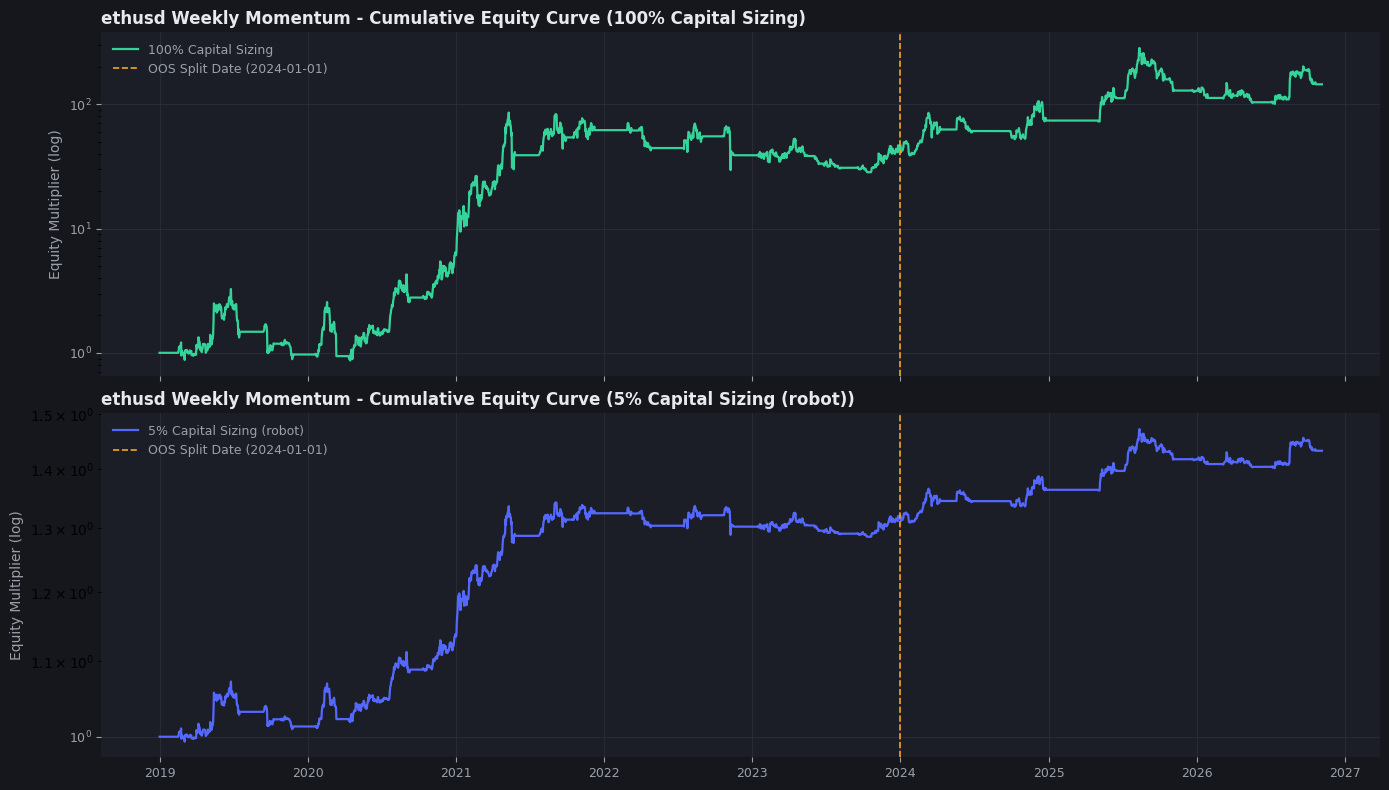

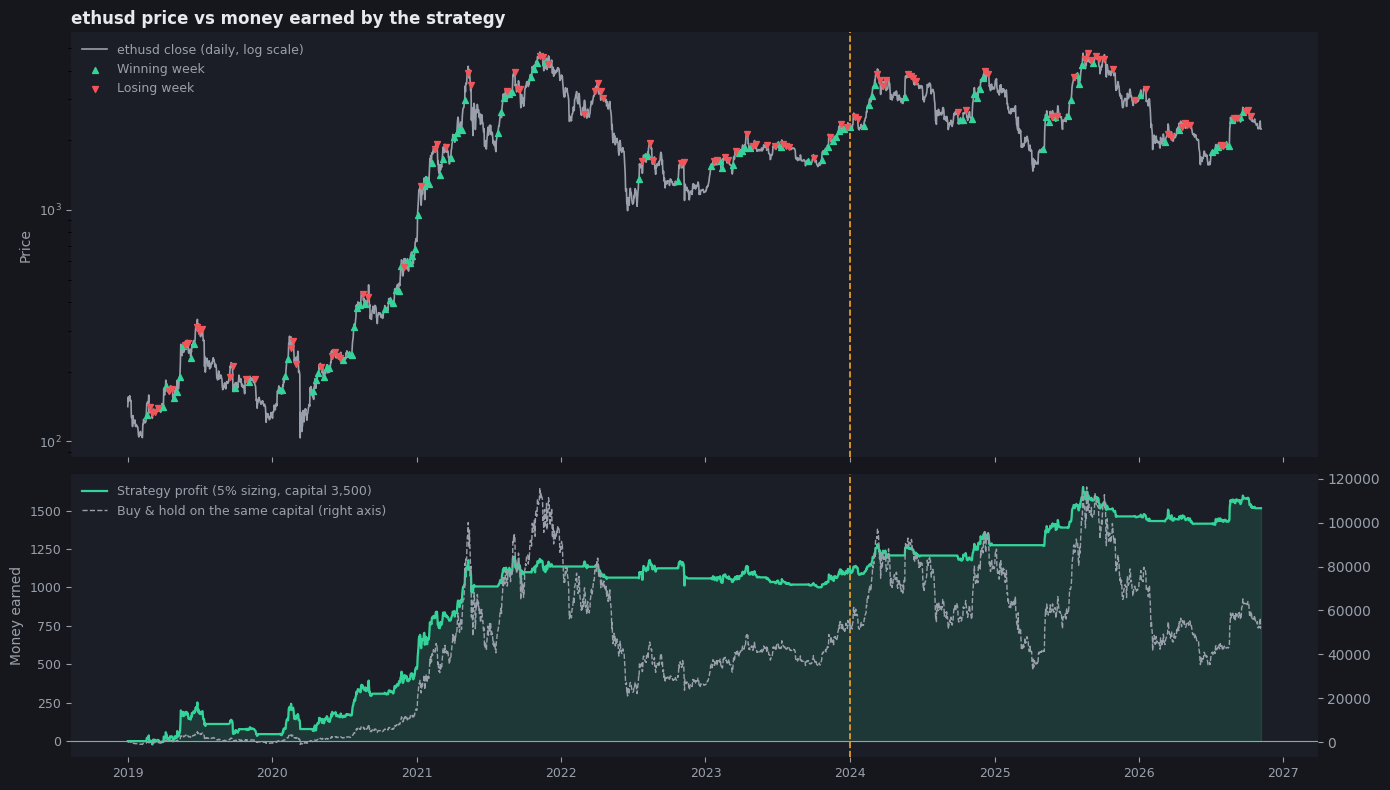

ethusd price change: +1,482% | strategy profit (fraction sizing, 3,500): 1,515 (+43.3%) | buy & hold profit: 51,875 | time in market: 84.9%

CHECKS (section 5):
   [PASS] Profit Factor, full period >= 1.3  ->  PF = 1.886
   [PASS] Profit Factor, IS >= 1.3  ->  PF = 1.989
   [PASS] Profit Factor, OOS >= 1.3  ->  PF = 1.646
   [PASS] OOS does not degrade vs IS (OOS PF >= 50% of IS PF)  ->  OOS 1.646 vs IS 1.989
   [PASS] t-stat of the mean trade >= 2  ->  t = 3.25
   [PASS] Trades, full period >= 100  ->  221 trades
   [PASS] Trades, OOS >= 30  ->  72 trades
   [PASS] Expectancy > 0 in IS and OOS (net of spread and swap)  ->  IS +3.841% | OOS +2.227%
   [FAIL] Strict research gate: t-stat >= 2 in IS and in OOS  ->  IS t = 2.89 | OOS t = 1.49


'FAIL'

In [37]:
def sized(t, sizing):
    return t if sizing == "capital" else t.assign(pnl=t["pnl_frac"], win=t["pnl_frac"] > 0)

def perf_row(t, d_slice, period, sizing):
    # The MTM series is built on the FULL df (trade positions refer to it) and then cut to the period dates
    m = compute_metrics(sized(t, sizing), contract_multiplier=1.0, cost_per_trade=0.0)
    ret = eng.daily_returns(df, t, sizing=sizing)
    lo, hi = d_slice.index[0].normalize(), d_slice.index[-1]
    ret = ret[(ret.index >= lo) & (ret.index <= hi)]
    eq = (1.0 + ret).cumprod()
    yrs = (hi - d_slice.index[0]).days / 365.25
    return {"Period": period, "Sizing": "100% Capital" if sizing == "capital" else f"{SIZE_FRAC:.0%} Capital (robot)",
            "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%", "Profit Factor": f"{m['profit_factor']:.3f}",
            "Expectancy": f"{m['expectancy']:.3f}%", "Total Return": f"{(eq.iloc[-1] - 1) * 100:.1f}%",
            "CAGR": f"{((eq.iloc[-1] ** (1 / yrs)) - 1) * 100:.1f}%" if yrs > 0 else "n/a",
            "Sharpe": f"{sharpe_ratio(ret, periods_per_year=PPY):.2f}", "Max Drawdown": f"{max_drawdown(eq) * 100:.2f}%"}

periods = [(f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", trades_is, df_is),
           (f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", trades_oos, df_oos),
           (f"Full Period ({df.index[0].year}-{df.index[-1].year})", trades_all, df)]
perf_table = pd.DataFrame([perf_row(t, d, name, s) for name, t, d in periods for s in ("capital", "fraction")])

print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF SPREAD AND SWAP · daily MTM drawdown, Sharpe annualised x{PPY})")
print("=" * 80)
display(perf_table)

ret_cap = eng.daily_returns(df, trades_all, sizing="capital")
ret_fr = eng.daily_returns(df, trades_all, sizing="fraction")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor=BG)
for ax, r, col, lab in ((ax1, ret_cap, GREEN, "100% Capital Sizing"), (ax2, ret_fr, "#5468ff", f"{SIZE_FRAC:.0%} Capital Sizing (robot)")):
    dark_ax(ax)
    ax.plot(r.index, (1 + r).cumprod(), color=col, lw=1.6, label=lab)
    ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label=f"OOS Split Date ({oos_start:%Y-%m-%d})")
    ax.set_title(f"{TICKER} Weekly Momentum - Cumulative Equity Curve ({lab})", color=TXT, fontweight="bold", loc="left")
    ax.set_ylabel("Equity Multiplier (log)", color=SUB)
    ax.set_yscale("log")
    ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

profit_usd = CAPITAL * ((1.0 + ret_fr).cumprod() - 1.0)
price_daily = df["close"].resample("D").last().reindex(ret_fr.index).ffill().bfill()
buy_hold = CAPITAL * (price_daily / price_daily.iloc[0] - 1.0)
entries = trades_all.assign(entry_time=pd.to_datetime(trades_all["entry_time"])).set_index("entry_time")
won = entries["pnl"] > 0

fig, (ax_px, ax_pl) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor=BG, gridspec_kw={"height_ratios": [3, 2]})
for ax in (ax_px, ax_pl):
    dark_ax(ax)
    ax.grid(False)
    ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2)
ax_px.plot(price_daily.index, price_daily, color=SUB, lw=1.2, label=f"{TICKER} close (daily, log scale)")
ax_px.set_yscale("log")
ax_px.scatter(entries.index[won], entries.loc[won, "entry_price"], marker="^", s=18, color=GREEN, zorder=3, label="Winning week")
ax_px.scatter(entries.index[~won], entries.loc[~won, "entry_price"], marker="v", s=18, color=RED, zorder=3, label="Losing week")
ax_px.set_title(f"{TICKER} price vs money earned by the strategy", color=TXT, fontweight="bold", loc="left")
ax_px.set_ylabel("Price", color=SUB)
ax_px.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
ax_pl.plot(profit_usd.index, profit_usd, color=GREEN, lw=1.6, label=f"Strategy profit ({SIZE_FRAC:.0%} sizing, capital {CAPITAL:,.0f})")
ax_pl.fill_between(profit_usd.index, profit_usd, 0, color=GREEN, alpha=0.15)
ax_pl.axhline(0, color=SUB, lw=0.8)
ax_pl.set_ylabel("Money earned", color=SUB)
ax_bh = ax_pl.twinx()
ax_bh.plot(buy_hold.index, buy_hold, color=SUB, lw=1.0, ls="--", label="Buy & hold on the same capital (right axis)")
ax_bh.grid(False)
ax_bh.tick_params(colors=SUB)
for spine in ax_bh.spines.values():
    spine.set_visible(False)
h1, l1 = ax_pl.get_legend_handles_labels()
h2, l2 = ax_bh.get_legend_handles_labels()
ax_pl.legend(h1 + h2, l1 + l2, frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

in_market = float(trades_all["bars"].sum()) / len(df)
print(f"{TICKER} price change: {(price_daily.iloc[-1] / price_daily.iloc[0] - 1) * 100:+,.0f}% | "
      f"strategy profit (fraction sizing, {CAPITAL:,.0f}): {profit_usd.iloc[-1]:,.0f} ({profit_usd.iloc[-1] / CAPITAL * 100:+.1f}%) | "
      f"buy & hold profit: {buy_hold.iloc[-1]:,.0f} | time in market: {in_market * 100:.1f}%")

# ---- PASS / FAIL ----
print("\nCHECKS (section 5):")
m_all, m_is, m_oos = (compute_metrics(t, 1.0, 0.0) for t in (trades_all, trades_is, trades_oos))
t_all, t_is, t_oos = tstat(trades_all["pnl"]), tstat(trades_is["pnl"]), tstat(trades_oos["pnl"])
check("5. Baseline", f"Profit Factor, full period >= {PF_MIN:g}", m_all["profit_factor"] >= PF_MIN, f"PF = {m_all['profit_factor']:.3f}")
check("5. Baseline", f"Profit Factor, IS >= {PF_MIN:g}", m_is["profit_factor"] >= PF_MIN, f"PF = {m_is['profit_factor']:.3f}")
check("5. Baseline", f"Profit Factor, OOS >= {PF_MIN:g}", m_oos["profit_factor"] >= PF_MIN, f"PF = {m_oos['profit_factor']:.3f}")
check("5. Baseline", "OOS does not degrade vs IS (OOS PF >= 50% of IS PF)", m_oos["profit_factor"] >= 0.5 * m_is["profit_factor"],
      f"OOS {m_oos['profit_factor']:.3f} vs IS {m_is['profit_factor']:.3f}")
check("5. Baseline", f"t-stat of the mean trade >= {T_MIN:g}", t_all >= T_MIN, f"t = {t_all:.2f}")
check("5. Baseline", f"Trades, full period >= {N_MIN}", m_all["num_trades"] >= N_MIN, f"{m_all['num_trades']} trades")
check("5. Baseline", f"Trades, OOS >= {N_OOS_MIN}", m_oos["num_trades"] >= N_OOS_MIN, f"{m_oos['num_trades']} trades")
check("5. Baseline", "Expectancy > 0 in IS and OOS (net of spread and swap)", m_is["expectancy"] > 0 and m_oos["expectancy"] > 0,
      f"IS {m_is['expectancy']:+.3f}% | OOS {m_oos['expectancy']:+.3f}%")
# Edge-specific (the research status is 'conditional candidate' because of this gate): informative, never hidden
check("5. Baseline", f"Strict research gate: t-stat >= {T_MIN:g} in IS and in OOS", t_is >= T_MIN and t_oos >= T_MIN,
      f"IS t = {t_is:.2f} | OOS t = {t_oos:.2f}")

## 5.1 LOT-ADJUSTED SIZING AND HARD LIMIT (CFD)

HARD LIMIT -9% · LOT-ADJUSTED SIZING (min lot 0.1, step 0.1)


,Sizing,Trades taken,Total Return,Max DD (hourly MTM),Headroom,Hard limit
0,5% ideal fraction,221,43.3%,-6.53%,+2.47 pts,PASS
1,"Lot-adjusted (capital 3,500)",221,31.2%,-8.68%,+0.32 pts,PASS


Minimum capital so the minimum lot weighs <= 5% at 2,234: 4,467
Largest fixed fraction that keeps the hourly drawdown inside -9%: 7.0% (configured: 5%)
Trades forced to the minimum lot (the fraction would give less than 0.1): 91 of 221
Lots per trade: min 0.1 | median 0.1 | max 1.3

MINIMUM LOT (0.1 ETH) ON EVERY TRADE: DRAWDOWN BY CAPITAL


,Capital,Lots,Max DD (closes),Max DD (intra-candle),Hard limit
0,1000,0.1,-24.1%,-24.4%,FAIL
1,1500,0.1,-18.5%,-18.8%,FAIL
2,2000,0.1,-15.0%,-15.3%,FAIL
3,3000,0.1,-10.9%,-11.1%,FAIL
4,4000,0.1,-8.6%,-8.7%,PASS
5,5000,0.1,-7.1%,-7.2%,PASS
6,6000,0.1,-6.0%,-6.1%,PASS
7,8000,0.1,-4.6%,-4.7%,PASS
8,10000,0.1,-3.7%,-3.8%,PASS


Smallest capital in the grid that respects -9% (intra-candle) with the minimum lot: 4000

CHECKS (5.1):
   [PASS] 5% ideal fraction stays inside -9%  ->  max DD -6.53% | headroom +2.47 pts
   [PASS] Lot-adjusted sizing stays inside -9%  ->  max DD -8.68% at capital 3,500 | headroom +0.32 pts
   [PASS] Configured fraction <= largest fraction allowed by the limit  ->  5% vs 7.0%
   [FAIL] Capital >= minimum capital for the minimum lot  ->  3,500 vs 4,467
   [PASS] Every trade is executable with the minimum lot  ->  221 of 221 trades taken
   [PASS] Intrabar drawdown (candle lows/highs) stays inside -9%  ->  max DD intrabar -8.80% (closes only -8.68%) | headroom +0.20 pts
   [FAIL] Capital reaches the capital the hard limit needs with the minimum lot  ->  needed 4000 vs capital 3,500


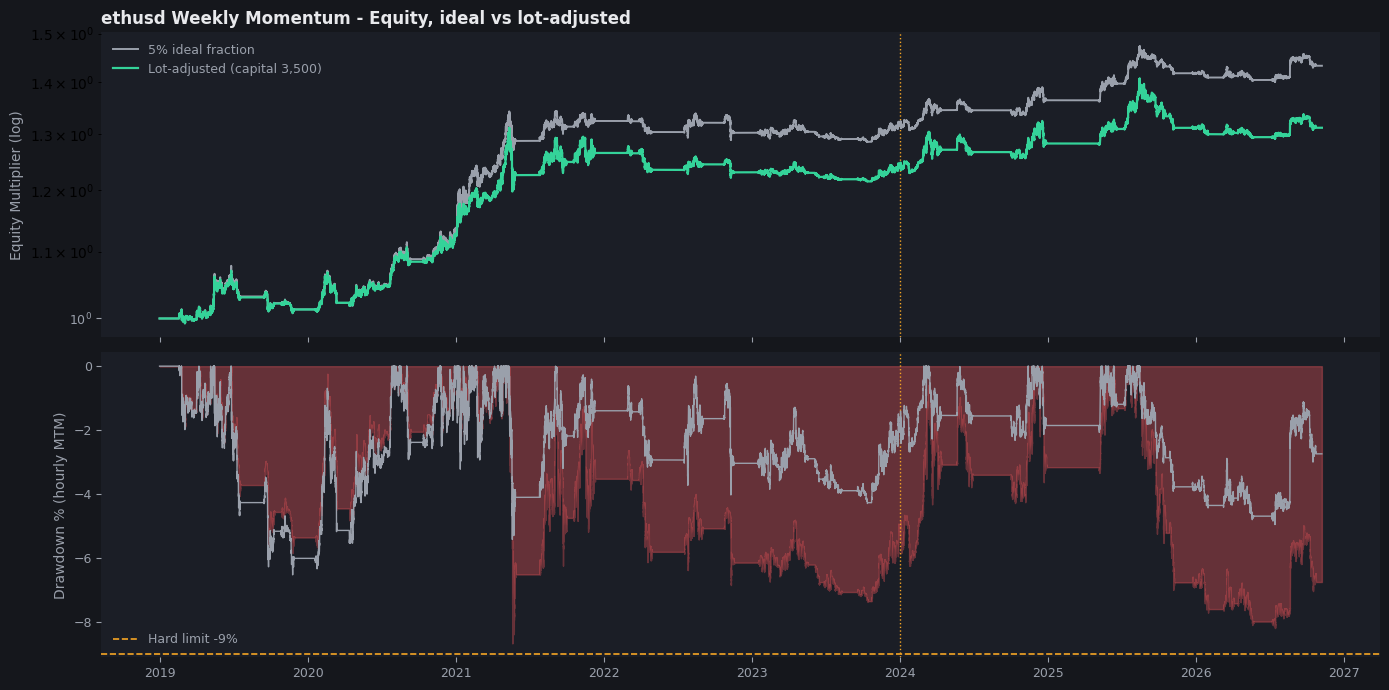

In [38]:
last_price = float(df["close"].iloc[-1])
min_capital = eng.min_capital_for_target(last_price, SIZE_FRAC)
max_frac = eng.max_fraction_for_limit(df, trades_all, HARD_LIMIT)
lot_sizes = eng.cfd_trade_sizes(trades_all, CAPITAL, SIZE_FRAC)
sz_lot = lot_sizes["size_fraction"].to_numpy()
hourly_ideal = eng.hourly_returns(df, trades_all, sizing="fraction")
hourly_lot = eng.hourly_returns(df, trades_all, sizing=sz_lot)

def drawdown_series(hourly):
    eq = (1.0 + hourly).cumprod()
    return eq / np.maximum(eq.cummax(), 1.0) - 1.0

def limit_row(label, hourly, n_taken):
    rep = eng.hard_limit_report(hourly, HARD_LIMIT)
    total = (1.0 + hourly).prod() - 1.0
    return {"Sizing": label, "Trades taken": n_taken, "Total Return": f"{total * 100:.1f}%",
            "Max DD (hourly MTM)": f"{rep['max_dd'] * 100:.2f}%", "Headroom": f"{rep['headroom'] * 100:+.2f} pts",
            "Hard limit": "PASS" if rep["passed"] else "FAIL"}

limit_table = pd.DataFrame([
    limit_row(f"{SIZE_FRAC:.0%} ideal fraction", hourly_ideal, len(trades_all)),
    limit_row(f"Lot-adjusted (capital {CAPITAL:,.0f})", hourly_lot, int(lot_sizes["taken"].sum()))])

print("=" * 80)
print(f"HARD LIMIT -{HARD_LIMIT:.0%} · LOT-ADJUSTED SIZING (min lot {MIN_LOT:g}, step {LOT_STEP:g})")
print("=" * 80)
display(limit_table)
print(f"Minimum capital so the minimum lot weighs <= {SIZE_FRAC:.0%} at {last_price:,.0f}: {min_capital:,.0f}")
print(f"Largest fixed fraction that keeps the hourly drawdown inside -{HARD_LIMIT:.0%}: {max_frac:.1%} (configured: {SIZE_FRAC:.0%})")
print(f"Trades forced to the minimum lot (the fraction would give less than {MIN_LOT:g}): {int(lot_sizes['forced_min_lot'].sum())} of {len(lot_sizes)}")
print(f"Lots per trade: min {lot_sizes.loc[lot_sizes['taken'], 'lots'].min():g} | median {lot_sizes.loc[lot_sizes['taken'], 'lots'].median():g} | max {lot_sizes['lots'].max():g}")

# ---- How much capital does the hard limit really need when trading the MINIMUM lot (0.1 ETH)? ----
CAP_GRID = [1_000, 1_500, 2_000, 3_000, 4_000, 5_000, 6_000, 8_000, 10_000]
cap_rows = []
for cap in CAP_GRID:
    ls = eng.cfd_trade_sizes(trades_all, cap, target_fraction=0.0001, below_min_lot="min_lot")     # always the minimum lot
    rep_c = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, sizing=ls["size_fraction"].to_numpy())
    cap_rows.append({"Capital": cap, "Lots": ls["lots"].max(), "Max DD (closes)": f"{rep_c['max_dd_close'] * 100:.1f}%",
                     "Max DD (intra-candle)": f"{rep_c['max_dd'] * 100:.1f}%", "Hard limit": "PASS" if rep_c["passed"] else "FAIL"})
cap_table = pd.DataFrame(cap_rows)
print(f"\nMINIMUM LOT ({MIN_LOT:g} ETH) ON EVERY TRADE: DRAWDOWN BY CAPITAL")
display(cap_table)
ok_caps = [r["Capital"] for r in cap_rows if r["Hard limit"] == "PASS"]
cap_needed = ok_caps[0] if ok_caps else None
print(f"Smallest capital in the grid that respects -{HARD_LIMIT:.0%} (intra-candle) with the minimum lot: "
      f"{cap_needed if cap_needed is not None else '> ' + str(CAP_GRID[-1])}")

# ---- PASS / FAIL ----
print("\nCHECKS (5.1):")
rep_ideal = eng.hard_limit_report(hourly_ideal, HARD_LIMIT)
rep_lot = eng.hard_limit_report(hourly_lot, HARD_LIMIT)
rep_ib = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, sizing=sz_lot)
check("5.1 Hard limit", f"{SIZE_FRAC:.0%} ideal fraction stays inside -{HARD_LIMIT:.0%}", rep_ideal["passed"],
      f"max DD {rep_ideal['max_dd'] * 100:.2f}% | headroom {rep_ideal['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", f"Lot-adjusted sizing stays inside -{HARD_LIMIT:.0%}", rep_lot["passed"],
      f"max DD {rep_lot['max_dd'] * 100:.2f}% at capital {CAPITAL:,.0f} | headroom {rep_lot['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", "Configured fraction <= largest fraction allowed by the limit", SIZE_FRAC <= max_frac,
      f"{SIZE_FRAC:.0%} vs {max_frac:.1%}")
check("5.1 Hard limit", "Capital >= minimum capital for the minimum lot", CAPITAL >= min_capital,
      f"{CAPITAL:,.0f} vs {min_capital:,.0f}")
check("5.1 Hard limit", "Every trade is executable with the minimum lot", int(lot_sizes["taken"].sum()) == len(trades_all),
      f"{int(lot_sizes['taken'].sum())} of {len(trades_all)} trades taken")
check("5.1 Hard limit", f"Intrabar drawdown (candle lows/highs) stays inside -{HARD_LIMIT:.0%}", rep_ib["passed"],
      f"max DD intrabar {rep_ib['max_dd'] * 100:.2f}% (closes only {rep_ib['max_dd_close'] * 100:.2f}%) | headroom {rep_ib['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", "Capital reaches the capital the hard limit needs with the minimum lot", cap_needed is not None and CAPITAL >= cap_needed,
      f"needed {cap_needed if cap_needed is not None else '> ' + str(CAP_GRID[-1])} vs capital {CAPITAL:,.0f}")

dd_ideal, dd_lot = drawdown_series(hourly_ideal), drawdown_series(hourly_lot)
fig, (ax_eq, ax_dd) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, facecolor=BG)
for ax in (ax_eq, ax_dd):
    dark_ax(ax)
    ax.grid(False)
    ax.axvline(oos_start, color=ORANGE, ls=":", lw=1.0)
ax_eq.plot(hourly_ideal.index, (1.0 + hourly_ideal).cumprod(), color=SUB, lw=1.4, label=f"{SIZE_FRAC:.0%} ideal fraction")
ax_eq.plot(hourly_lot.index, (1.0 + hourly_lot).cumprod(), color=GREEN, lw=1.6, label=f"Lot-adjusted (capital {CAPITAL:,.0f})")
ax_eq.set_yscale("log")
ax_eq.set_title(f"{TICKER} Weekly Momentum - Equity, ideal vs lot-adjusted", color=TXT, fontweight="bold", loc="left")
ax_eq.set_ylabel("Equity Multiplier (log)", color=SUB)
ax_eq.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
ax_dd.plot(dd_ideal.index, dd_ideal * 100, color=SUB, lw=1.0)
ax_dd.fill_between(dd_lot.index, dd_lot * 100, 0, color=RED, alpha=0.35)
ax_dd.axhline(-HARD_LIMIT * 100, color=ORANGE, ls="--", lw=1.2, label=f"Hard limit -{HARD_LIMIT:.0%}")
ax_dd.set_ylabel("Drawdown % (hourly MTM)", color=SUB)
ax_dd.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

## 5.2 ANNUAL RETURNS AND HARD LIMIT CHECK

ANNUAL RETURNS · LOT-ADJUSTED (capital 3,500) · HARD LIMIT -9% · partial = incomplete calendar year


,year,ret,mdd,n_trades,partial,breach
0,2019,1.3%,-5.8%,26,False,False
1,2020,11.1%,-4.6%,38,False,False
2,2021,12.4%,-8.7%,35,False,False
3,2022,-2.7%,-4.3%,14,False,False
4,2023,0.7%,-2.7%,36,False,False
5,2024,3.4%,-3.8%,26,False,False
6,2025,2.2%,-7.0%,21,False,False
7,2026,0.1%,-2.2%,25,True,False


Steps below the limit: 0 | first breach: None

CHECKS (5.2):
   [PASS] No calendar year breaches the hard limit  ->  years in breach: none | worst year DD -8.7%
   [PASS] >= 75% of full calendar years are profitable  ->  6/7 full years positive | non-positive: 2022 (-2.7%)


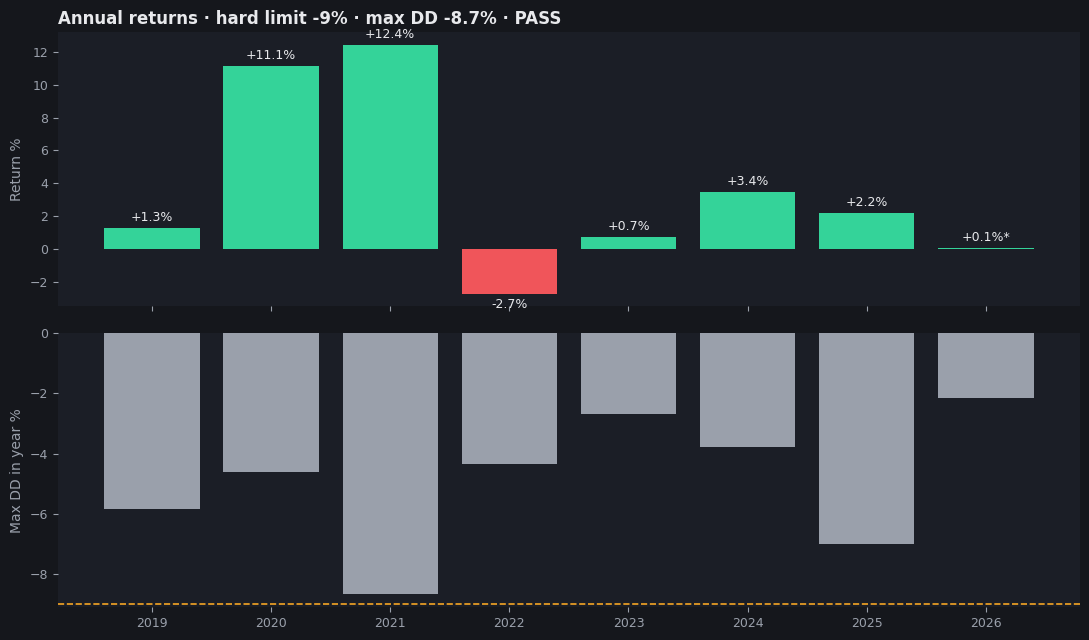

In [39]:
def plot_annual_returns(annual, report, hard_limit):
    fig, (ax_ret, ax_dd) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, facecolor=BG)
    years = annual["year"].astype(str).to_numpy()
    ret_colors = [GREEN if v >= 0 else RED for v in annual["ret"]]
    bars = ax_ret.bar(years, annual["ret"] * 100, color=ret_colors)
    dd_colors = [RED if b else SUB for b in annual["breach"]]
    ax_dd.bar(years, annual["mdd"] * 100, color=dd_colors)
    ax_dd.axhline(-hard_limit * 100, color=ORANGE, ls="--", lw=1.2)
    for ax in (ax_ret, ax_dd):
        dark_ax(ax)
        ax.grid(False)
    for rect, value, partial in zip(bars, annual["ret"], annual["partial"]):
        label = f"{value:+.1%}" + ("*" if partial else "")
        ax_ret.annotate(label, (rect.get_x() + rect.get_width() / 2, value * 100),
                        xytext=(0, 3 if value >= 0 else -3), textcoords="offset points",
                        ha="center", va="bottom" if value >= 0 else "top", color=TXT, fontsize=9)
    status = "PASS" if report["passed"] else "FAIL"
    ax_ret.set_title(f"Annual returns · hard limit -{hard_limit:.0%} · max DD {report['max_dd']:.1%} · {status}",
                     color=TXT, fontweight="bold", loc="left")
    ax_ret.set_ylabel("Return %", color=SUB)
    ax_dd.set_ylabel("Max DD in year %", color=SUB)
    plt.tight_layout(); plt.show()

annual = eng.annual_returns(hourly_lot, trades_all, HARD_LIMIT)
report_annual = eng.hard_limit_report(hourly_lot, HARD_LIMIT)
disp = annual.assign(ret=(annual["ret"] * 100).round(1).astype(str) + "%", mdd=(annual["mdd"] * 100).round(1).astype(str) + "%")

print("=" * 80)
print(f"ANNUAL RETURNS · LOT-ADJUSTED (capital {CAPITAL:,.0f}) · HARD LIMIT -{HARD_LIMIT:.0%} · partial = incomplete calendar year")
print("=" * 80)
display(disp)
print(f"Steps below the limit: {report_annual['steps_in_breach']} | first breach: {report_annual['first_breach']}")

# ---- PASS / FAIL ----
print("\nCHECKS (5.2):")
full_y = annual[~annual["partial"]]
neg = full_y[full_y["ret"] <= 0]
n_pos = len(full_y) - len(neg)
breach_years = annual.loc[annual["breach"], "year"].astype(int).tolist()
check("5.2 Annual", "No calendar year breaches the hard limit", not annual["breach"].any(),
      f"years in breach: {breach_years if breach_years else 'none'} | worst year DD {annual['mdd'].min() * 100:.1f}%")
check("5.2 Annual", f">= {YEARS_POS_MIN:.0%} of full calendar years are profitable", len(full_y) > 0 and n_pos / len(full_y) >= YEARS_POS_MIN,
      f"{n_pos}/{len(full_y)} full years positive" + (" | non-positive: " + ", ".join(f"{int(y)} ({r:+.1%})" for y, r in zip(neg["year"], neg["ret"])) if len(neg) else ""))

plot_annual_returns(annual, report_annual, HARD_LIMIT)

## 6. SANITY CHECKS & VERIFICATION

In [40]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. No lookahead + execution model (violations are collected, not asserted, so the notebook keeps running)
violations, prev_end = [], None
srv = df["srv_time"]
sp, o = df["spread_px"].to_numpy(float), df["open"].to_numpy(float)
for idx_, r in trades_all.iterrows():
    i0, i1 = int(r["i_ent"]), int(r["i_sal"])
    et, xt = pd.Timestamp(r["entry_time"]), pd.Timestamp(r["exit_time"])
    if df.index[i0] != et or df.index[i1] != xt:
        violations.append(f"trade {idx_}: i_ent / i_sal misaligned")
    if df.index[i0] - df.index[i0 - 1] != pd.Timedelta(hours=1):
        violations.append(f"trade {idx_}: signal bar is not the previous hour")
    s0, s1 = pd.Timestamp(srv.iloc[i0]), pd.Timestamp(srv.iloc[i1])
    if not (s0.dayofweek == ENTRY_DOW and s0.hour == ENTRY_HOUR and s0.minute == 0):
        violations.append(f"trade {idx_}: entry is not Monday {ENTRY_HOUR:02d}:00 server time")
    if s1 - s0 != pd.Timedelta(days=HOLD):
        violations.append(f"trade {idx_}: holding is not {HOLD} days of server time")
    long_ = r["side"] > 0
    exp_e = o[i0] + sp[i0] if long_ else o[i0]
    exp_x = o[i1] if long_ else o[i1] + sp[i1]
    if not (np.isclose(r["entry_price"], exp_e, atol=1e-6) and np.isclose(r["exit_price"], exp_x, atol=1e-6)):
        violations.append(f"trade {idx_}: entry/exit price mismatch (long pays the ENTRY spread, short the EXIT spread)")
    if (r["mom_ret"] > 0) != long_:
        violations.append(f"trade {idx_}: direction does not follow the sign of the momentum")
    if HOLD <= 7 and prev_end is not None and et < prev_end:      # with hold > 7 the overlap is by design
        violations.append(f"trade {idx_}: overlaps the previous trade")
    prev_end = xt
MAX_CONC = -(-HOLD // 7)                                          # ceil(HOLD / 7)
conc = eng.max_concurrent(trades_all)
if conc > MAX_CONC:
    violations.append(f"{conc} trades open at once, expected at most {MAX_CONC} for a {HOLD}-day hold")
overlap_txt = "no overlap" if HOLD <= 7 else f"at most {MAX_CONC} concurrent trades (max seen {conc})"
print(f"Sanity Check 1: no lookahead, Monday {ENTRY_HOUR:02d}:00 server entry, {HOLD} d hold, {overlap_txt} ({len(trades_all)} trades).")
print("   - Signal evaluated at the close of the previous hourly bar (Sunday 21:00/22:00 UTC).")
print("   - Execution at the open: long pays the entry-candle spread, short pays the exit-candle spread.")
check("6. Sanity", "No lookahead and execution model respected on every trade", not violations,
      f"{len(trades_all)} trades checked" + (f" | {len(violations)} violations, first: {violations[0]}" if violations else ""))

# 2. Data coverage per calendar year (full years only): signal weeks (both signs) and traded weeks
trades_all["year"] = pd.to_datetime(trades_all["entry_time"]).dt.year
tpy = trades_all.groupby("year").size()
spy = pd.to_datetime(trades_sig["entry_time"]).dt.year.value_counts().sort_index()
full_years = [y for y in range(df.index[0].year, df.index[-1].year + 1)
              if pd.Timestamp(f"{y}-01-01") >= df.index[0] and pd.Timestamp(f"{y}-12-31") <= df.index[-1]]
tpy_full, spy_full = tpy.reindex(full_years, fill_value=0), spy.reindex(full_years, fill_value=0)
print("\nSanity Check 2: Signal weeks and trades per year:")
print(f"   - Signal weeks (both signs) min/max per full year: {spy_full.min()} ({spy_full.idxmin()}) / {spy_full.max()} ({spy_full.idxmax()})")
print(f"   - Traded weeks ({DIRECTION}): average {tpy.mean():.1f} | min (full years) {tpy_full.min()} ({tpy_full.idxmin()}) | max {tpy.max()} ({tpy.idxmax()})")
check("6. Sanity", f"Every full calendar year has >= {MIN_TRADES_PER_YEAR:g} signal weeks (both signs)", (spy_full >= MIN_TRADES_PER_YEAR).all(),
      f"min {spy_full.min()} ({spy_full.idxmin()}) | traded min {tpy_full.min()} ({tpy_full.idxmin()})")

# 3. MTM paths reproduce the trade returns exactly (also for shorts, with swap)
paths = eng.trade_mtm_paths(df, trades_all, sizing="capital")
err = max(abs(np.prod(1 + p) - (1 + pnl / 100)) for p, pnl in zip(paths, trades_all["pnl"]))
print(f"\nSanity Check 3: MTM paths telescope to trade returns (max abs error {err:.2e}).")
check("6. Sanity", "MTM paths telescope to the trade returns (error < 1e-9)", err < 1e-9, f"max abs error {err:.2e}")

# 4. Swap bookkeeping: one rollover per calendar night of server time (Mon-Thu x1, Fri x3, Sat/Sun x0)
print(f"\nSanity Check 4: rollovers crossed per trade: min {int(trades_all['n_rolls'].min())} | max {int(trades_all['n_rolls'].max())} (a {HOLD}-day hold crosses {HOLD}).")
check("6. Sanity", f"Swap is charged: every trade crosses {HOLD - 1}-{HOLD + 1} rollovers", trades_all["n_rolls"].between(HOLD - 1, HOLD + 1).all(),
      f"n_rolls min {int(trades_all['n_rolls'].min())} / max {int(trades_all['n_rolls'].max())}")

# 5. Cross-check with the research (same rules, Axi ETHUSD H1)
print("\nSanity Check 5: Comparison with the research reference:")
if is_reference:
    n_oos_ours, mean_oos_ours = len(trades_oos), float(trades_oos["pnl"].mean())
    check("6. Sanity", f"Matches the research reference: Trades, OOS (±{REF_TOL_TRADES:.0%})", abs(n_oos_ours / REF_OOS_N - 1) <= REF_TOL_TRADES,
          f"ours {n_oos_ours} vs research {REF_OOS_N} ({n_oos_ours / REF_OOS_N - 1:+.0%})")
    check("6. Sanity", f"Matches the research reference: mean net pnl, OOS (±{REF_TOL_MEAN:.0%})", abs(mean_oos_ours / REF_OOS_NET_PCT - 1) <= REF_TOL_MEAN,
          f"ours {mean_oos_ours:+.3f}% vs research {REF_OOS_NET_PCT:+.3f}%")
else:
    check("6. Sanity", "Matches the research reference", None, "skipped: not the research rules (28 d / 7 d / both / spread)")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: no lookahead, Monday 00:00 server entry, 11 d hold, at most 2 concurrent trades (max seen 2) (221 trades).
   - Signal evaluated at the close of the previous hourly bar (Sunday 21:00/22:00 UTC).
   - Execution at the open: long pays the entry-candle spread, short pays the exit-candle spread.
   [PASS] No lookahead and execution model respected on every trade  ->  221 trades checked

Sanity Check 2: Signal weeks and trades per year:
   - Signal weeks (both signs) min/max per full year: 48 (2019) / 53 (2023)
   - Traded weeks (long_only): average 27.6 | min (full years) 14 (2022) | max 38 (2020)
   [PASS] Every full calendar year has >= 40 signal weeks (both signs)  ->  min 48 (2019) | traded min 14 (2022)

Sanity Check 3: MTM paths telescope to trade returns (max abs error 5.33e-15).
   [PASS] MTM paths telescope to the trade returns (error < 1e-9)  ->  max abs error 5.33e-15

Sanity Check 4: rollovers crossed per trade: min 11 | max 11 (a

## 7. REFERENCE VARIANTS: THE TRADED RULE VS THE OTHER DIRECTIONS (SAME BARS, SAME COSTS, SAME SIZE)

Same logic as "v3 vs naked vs v1" in the Monday Effect notebook: the rule that is traded must beat the alternatives it could have been. The alternatives are the **other directions** of the same momentum signal (both legs / long only / short only). The passive "always long" benchmark is in 4.2, because it needs no extra engine run.

VARIANT COMPARISON (5% capital per trade, net of spread and swap unless stated)


,Trades,PF,Expectancy %,t-stat,Sharpe,Max DD %,Final capital x
Variant,,,,,,,
Both legs,403,1.418,1.840,2.551,0.770,-7.882,1.433
Long only (traded),221,1.886,3.315,3.253,0.919,-5.815,1.433
Short only,182,1.009,0.049,0.049,0.022,-9.921,1.000
"Long only, NO swap (diagnostic)",221,2.130,3.931,3.846,1.087,-5.583,1.534


Swap cost per trade (Long only): 0.616% of the notional per week

CHECKS (section 7):
   [PASS] Configured rule beats the other directions on Profit Factor  ->  Long only (traded) 1.886 | Both legs 1.418 | Short only 1.009
   [PASS] Configured rule beats the other directions on expectancy per trade  ->  Long only (traded) +3.315% | Both legs +1.840% | Short only +0.049%
   [PASS] Configured rule beats the other directions on Sharpe  ->  Long only (traded) 0.92 | Both legs 0.77 | Short only 0.02
   [PASS] Configured rule max drawdown is shallower than the other directions  ->  Long only (traded) -5.8% | Both legs -7.9% | Short only -9.9%
   [PASS] Configured rule final capital is not below the other directions (1% tolerance)  ->  Long only (traded) 1.433x | Both legs 1.433x | Short only 1.000x


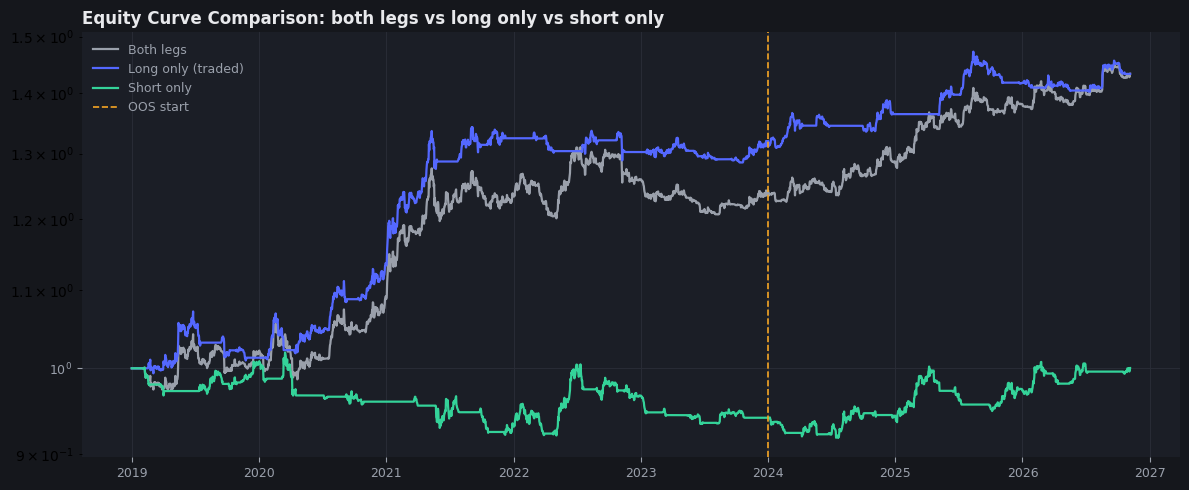

In [41]:
DIRS = {"both": "Both legs", "long_only": "Long only", "short_only": "Short only"}
dir_trades = {"both": trades_sig}
for d in ("long_only", "short_only"):
    dir_trades[d] = trades_all if d == DIRECTION else eng.run_weekly_backtest(df, **{**RULES, "direction": d})

def variant_row(label, t, price_df):
    m = compute_metrics(t, 1.0, 0.0)
    ret = eng.daily_returns(price_df, t, sizing="fraction")
    eq = (1.0 + ret).cumprod()
    return {"Variant": label, "Trades": m["num_trades"], "PF": m["profit_factor"], "Expectancy %": m["expectancy"],
            "t-stat": tstat(t["pnl"]), "Sharpe": sharpe_ratio(ret, periods_per_year=PPY),
            "Max DD %": max_drawdown(eq) * 100, "Final capital x": float(eq.iloc[-1])}, eq

var_rows, var_curves, var_raw = [], {}, {}
for d, label in DIRS.items():
    lab = label + (" (traded)" if d == DIRECTION else "")
    row, eq = variant_row(lab, dir_trades[d], df)
    var_rows.append(row)
    var_curves[lab] = eq
    var_raw[d] = {"pf": row["PF"], "exp": row["Expectancy %"], "sharpe": row["Sharpe"], "mdd": row["Max DD %"], "final": row["Final capital x"]}

_old_swap = eng.ENGINE_DEFAULTS["use_swap"]
eng.set_engine_defaults(use_swap=False)          # diagnostic: the MTM path must also ignore the swap
try:
    t_noswap = eng.run_weekly_backtest(df, **RULES)
    row_noswap, _ = variant_row(f"{DIRS[DIRECTION]}, NO swap (diagnostic)", t_noswap, df)
finally:
    eng.set_engine_defaults(use_swap=_old_swap)
var_table = pd.DataFrame(var_rows + [row_noswap]).set_index("Variant")

print("=" * 80)
print(f"VARIANT COMPARISON ({SIZE_FRAC:.0%} capital per trade, net of spread and swap unless stated)")
print("=" * 80)
display(var_table.round(3))
swap_cost = row_noswap["Expectancy %"] - var_raw[DIRECTION]["exp"]
print(f"Swap cost per trade ({DIRS[DIRECTION]}): {swap_cost:.3f}% of the notional per week")

# ---- PASS / FAIL ----
print("\nCHECKS (section 7):")
cv = var_raw[DIRECTION]
others = [d for d in DIRS if d != DIRECTION]
def _detail(key, fmt):
    return f"{DIRS[DIRECTION]} (traded) {fmt.format(cv[key])} | " + " | ".join(f"{DIRS[d]} {fmt.format(var_raw[d][key])}" for d in others)

check("7. Variants", "Configured rule beats the other directions on Profit Factor", all(cv["pf"] > var_raw[d]["pf"] for d in others), _detail("pf", "{:.3f}"))
check("7. Variants", "Configured rule beats the other directions on expectancy per trade", all(cv["exp"] > var_raw[d]["exp"] for d in others), _detail("exp", "{:+.3f}%"))
check("7. Variants", "Configured rule beats the other directions on Sharpe", all(cv["sharpe"] > var_raw[d]["sharpe"] for d in others), _detail("sharpe", "{:.2f}"))
check("7. Variants", "Configured rule max drawdown is shallower than the other directions", all(cv["mdd"] > var_raw[d]["mdd"] for d in others), _detail("mdd", "{:.1f}%"))
check("7. Variants", "Configured rule final capital is not below the other directions (1% tolerance)", all(cv["final"] >= var_raw[d]["final"] * 0.99 for d in others), _detail("final", "{:.3f}x"))

fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
dark_ax(ax)
for (name, eq), col in zip(var_curves.items(), (SUB, "#5468ff", GREEN)):
    ax.plot(eq.index, eq, color=col, lw=1.6, label=name)
ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label="OOS start")
ax.set_yscale("log")
ax.set_title("Equity Curve Comparison: both legs vs long only vs short only", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 8. SUMMARY OF HYPOTHESIS & NEXT STEPS

In [42]:
ret_fr_all = eng.daily_returns(df, trades_all, sizing="fraction")
max_dd_fr = max_drawdown((1 + ret_fr_all).cumprod()) * 100
years = (df.index[-1] - df.index[0]).days / 365.25
next_nb = "02_Weekly_Momentum_Optimization.ipynb"

# Core verdict (kept for the JSON of section 9): PF full and OOS, t-stat, N
confirmed = bool(m_all["profit_factor"] >= PF_MIN and m_oos["profit_factor"] >= PF_MIN and t_all >= T_MIN and m_all["num_trades"] >= N_MIN)
verdict = "Hypothesis Confirmed" if confirmed else "Hypothesis NOT clearly confirmed"
check("8. Verdict", f"Core criteria: PF >= {PF_MIN:g} (full and OOS), t >= {T_MIN:g}, N >= {N_MIN}", confirmed,
      f"PF {m_all['profit_factor']:.3f} / OOS {m_oos['profit_factor']:.3f} | t {t_all:.2f} | N {m_all['num_trades']}", quiet=True)

# ---- GO / STOP gate: only the checks that decide whether the research continues ----
# Same gate as Monday Effect. (section, start of the check name, what to do if it FAILS).
# The edge-specific slot (Monday: "kept Mondays beat skipped") is the permutation test: momentum must beat its own shuffled signals.
ESSENTIAL = [
    ("6. Sanity",       "No lookahead",                                          "Fix the execution model / lookahead first: every other number is invalid until this passes."),
    ("6. Sanity",       "Matches the research reference: Trades, OOS",           "Reconcile the engine with the research (same OOS trade count): review the clock, the gaps and instrument.start."),
    ("4.2 Excess",      f"Permutation p < {ALPHA:g} (all weeks)",                "Momentum does not beat a permutation of its own signals: the 'edge' may just be the ETH drift."),
    ("5. Baseline",     "Profit Factor, IS",                                     "Baseline does not hold in-sample: the hypothesis is not supported, rethink the rules before optimizing."),
    ("5. Baseline",     "Profit Factor, OOS",                                    "Baseline does not hold out-of-sample: do not optimize, the edge is not confirmed."),
    ("5. Baseline",     "t-stat of the mean trade",                              "The mean trade is not statistically significant: the edge could be noise."),
    ("5. Baseline",     "Trades, full period",                                   "Too few trades to conclude anything."),
    ("5. Baseline",     "Trades, OOS",                                           "Too few OOS trades to validate the edge."),
    ("7. Variants",     "Configured rule beats the other directions on Profit Factor", "The traded direction does not beat the other directions on Profit Factor: the rule is not justified."),
    ("7. Variants",     "Configured rule max drawdown is shallower",             "The traded direction does not reduce drawdown vs the other directions."),
    ("5.1 Hard limit",  "Lot-adjusted sizing stays inside",                      "Lot-adjusted sizing breaks the hard limit: raise the capital (see the capital table in 5.1) or do not trade it."),
    ("5.1 Hard limit",  "Capital >= minimum capital",                            "Capital is below what the minimum lot needs: raise capital or lower the target fraction."),
    ("5.2 Annual",      "No calendar year breaches",                             "A calendar year breaches the hard limit: review sizing or the rules of that year."),
]
# The research-reference check only applies to the research rules (28 d / 7 d / both / spread): do not gate on it for any other rules
if not is_reference:
    ESSENTIAL = [e for e in ESSENTIAL if not e[1].startswith("Matches the research reference")]

chk = pd.DataFrame(CHECKS)
n_pass, n_fail, n_skip = (int((chk["status"] == s).sum()) for s in ("PASS", "FAIL", "SKIP"))   # all checks (saved in section 9)
key = {(s, n): a for s, n, a in ESSENTIAL}
chk["essential"] = [any(sec == s and nm.startswith(n) for s, n, _ in ESSENTIAL) for sec, nm in zip(chk["section"], chk["name"])]
ess = chk[chk["essential"]]
other = chk[~chk["essential"] & (chk["section"] != "8. Verdict")]
missing = [f"{s}: {n}" for s, n, _ in ESSENTIAL if not ((chk["section"] == s) & chk["name"].str.startswith(n)).any()]
ess_fail = ess[ess["status"] == "FAIL"]
go = ess_fail.empty and not missing

print("=" * 80)
print("8. SUMMARY OF HYPOTHESIS & NEXT STEPS")
print("=" * 80)
print(f"\nDECISION: {'GO - continue the research' if go else 'STOP - fix the failed gates before continuing'}   "
      f"({int((ess['status'] == 'PASS').sum())} PASS / {len(ess_fail)} FAIL / {int((ess['status'] == 'SKIP').sum())} SKIP of {len(ESSENTIAL)} essential checks)"
      f"   |   {verdict}")
if missing:
    print("   Not run (run the sections above first): " + "; ".join(missing))

print("\n" + "-" * 80)
print("ESSENTIAL CHECKS")
print("-" * 80)
for sec, g in ess.groupby("section", sort=False):
    print(f"\n{sec}")
    for _, row in g.iterrows():
        print(f"   [{row['status']}] {row['name']}" + (f"  ->  {row['detail']}" if row["detail"] else ""))

print("\n" + "-" * 80)
print("OTHER CHECKS (informative: registered and visible, they do not decide GO / STOP)")
print("-" * 80)
for _, row in other.iterrows():
    print(f"   [{row['status']}] {row['section']} · {row['name']}" + (f"  ->  {row['detail']}" if row["detail"] else ""))

print("\n" + "-" * 80)
print("KEY FINDINGS")
print("-" * 80)
print(f"1. {verdict}: {m_all['num_trades']} trades ({DIRECTION}) over {years:.1f} years, win rate {m_all['win_rate']:.1f}%, Profit Factor {m_all['profit_factor']:.3f}")
print(f"   (IS {m_is['profit_factor']:.3f} / OOS {m_oos['profit_factor']:.3f}), t-stat of the mean trade {t_all:.2f} (IS {t_is:.2f} / OOS {t_oos:.2f}).")
print(f"2. Signal vs drift: Spearman rho {rho:+.3f} (p = {p_rho:.3f}); excess over the naked position {drift.loc['All', 'Excess over drift %']:+.2f}% per week; "
      f"permutation p = {drift.loc['IS', 'Perm p (1-sided)']:.3f} IS / {drift.loc['OOS', 'Perm p (1-sided)']:.3f} OOS / {drift.loc['All', 'Perm p (1-sided)']:.3f} all weeks.")
print(f"3. Concentration: net mean positive in {int((by_year['net'] > 0).sum())} of {len(by_year)} calendar years; best year {best_year}, "
      f"net t without it {tstat(rest['pnl']):.2f}.")
print(f"4. Risk at {SIZE_FRAC:.0%} sizing: max daily-MTM drawdown {max_dd_fr:.2f}%; lot-adjusted at capital {CAPITAL:,.0f}: {rep_lot['max_dd'] * 100:.2f}%; "
      f"hard limit -{HARD_LIMIT:.0%}; capital the limit needs with the minimum lot: {cap_needed if cap_needed is not None else '> ' + str(CAP_GRID[-1])}.")

print("\n" + "-" * 80)
print("NEXT STEPS")
print("-" * 80)
steps = [key[(r["section"], next(n for s, n, _ in ESSENTIAL if s == r["section"] and r["name"].startswith(n)))] for _, r in ess_fail.iterrows()]
if missing:
    steps.append("Run all the sections above so every essential check is evaluated.")
if go:
    steps.append(f"Proceed to {next_nb} to check that (lookback {LOOKBACK} d, hold {HOLD} d) sits on a broad, stable plateau on in-sample data.")
else:
    steps.append("Otherwise record the variant as rejected, or keep it as a conditional candidate with the capital shown in 5.1.")
for i, s in enumerate(steps, 1):
    print(f"{i}. {s}")

8. SUMMARY OF HYPOTHESIS & NEXT STEPS

DECISION: STOP - fix the failed gates before continuing   (11 PASS / 1 FAIL / 0 SKIP of 12 essential checks)   |   Hypothesis Confirmed

--------------------------------------------------------------------------------
ESSENTIAL CHECKS
--------------------------------------------------------------------------------

4.2 Excess
   [PASS] Permutation p < 0.05 (all weeks)  ->  p = 0.018

5. Baseline
   [PASS] Profit Factor, IS >= 1.3  ->  PF = 1.989
   [PASS] Profit Factor, OOS >= 1.3  ->  PF = 1.646
   [PASS] t-stat of the mean trade >= 2  ->  t = 3.25
   [PASS] Trades, full period >= 100  ->  221 trades
   [PASS] Trades, OOS >= 30  ->  72 trades

5.1 Hard limit
   [PASS] Lot-adjusted sizing stays inside -9%  ->  max DD -8.68% at capital 3,500 | headroom +0.32 pts
   [FAIL] Capital >= minimum capital for the minimum lot  ->  3,500 vs 4,467

5.2 Annual
   [PASS] No calendar year breaches the hard limit  ->  years in breach: none | worst year DD -8.7%


## 9. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [43]:
limit_report = eng.hard_limit_report(hourly_lot, HARD_LIMIT)

save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params": cfg["params"],
    "evaluation_rules": "Monday Effect final PASS / FAIL rules",
    "oos_start": str(oos_start.date()),
    "all": {"n": int(len(trades_all)), "pf": float(m_all["profit_factor"]), "win_rate": float(m_all["win_rate"]), "t_stat": float(t_all)},
    "is":  {"n": int(len(trades_is)),  "pf": float(m_is["profit_factor"]),  "t_stat": float(t_is)},
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"]), "t_stat": float(t_oos)},
    "max_dd_fraction_sizing_pct": float(max_dd_fr),
    "hard_limit": {"limit": float(HARD_LIMIT), "capital": float(CAPITAL), "max_dd_hourly_pct": float(limit_report["max_dd"] * 100),
                   "passed": bool(limit_report["passed"]), "capital_needed_min_lot": (None if cap_needed is None else float(cap_needed))},
    "excess_over_drift": drift.round(4).reset_index().to_dict(orient="records"),
    "legs": legs.round(4).reset_index().to_dict(orient="records"),
    "momentum_spearman": {"rho": float(rho), "p": float(p_rho)},
    "hypothesis_confirmed": bool(confirmed),
    "go": bool(go),
    "essential_failed": ess_fail["name"].tolist(),
    "checks_summary": {"pass": n_pass, "fail": n_fail, "skip": n_skip},
    "checks": CHECKS,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/runs/v2_ethusd_long/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/runs/v2_ethusd_long/01_hypothesis.json')